# 6.3


In [ ]:

import numpy as np 
import pandas as pd 
import seaborn as sns 


In [43]:
np.linspace(1,10,10)

array([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.])

[[1. 1.]
 [1. 1.]]


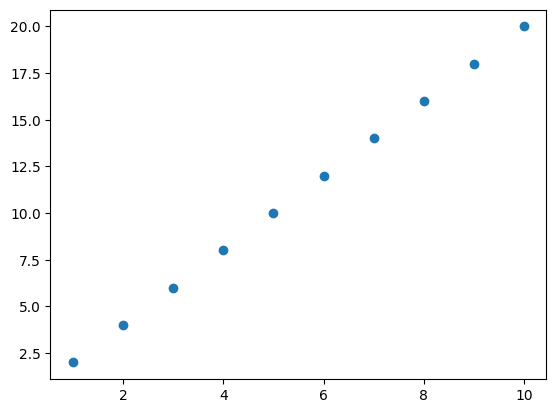

In [ ]:
def equ(m,x,c):
    y = m*x + c 
    return y 

m = 0 
x = np.linspace(1,10,10)
y = equ(2,x,0)

print(np.corrcoef(x,y))
plt.scatter(x,y)
plt.show()

In [48]:
data = {"X":x,"Y":y}
df = pd.DataFrame(data)
df

,X,Y
0,1.0,2.0
1,2.0,4.0
2,3.0,6.0
3,4.0,8.0
4,5.0,10.0
5,6.0,12.0
6,7.0,14.0
7,8.0,16.0
8,9.0,18.0
9,10.0,20.0


In [49]:
df.corr()

,X,Y
X,1.0,1.0
Y,1.0,1.0


[[ 1. -1.]
 [-1.  1.]]


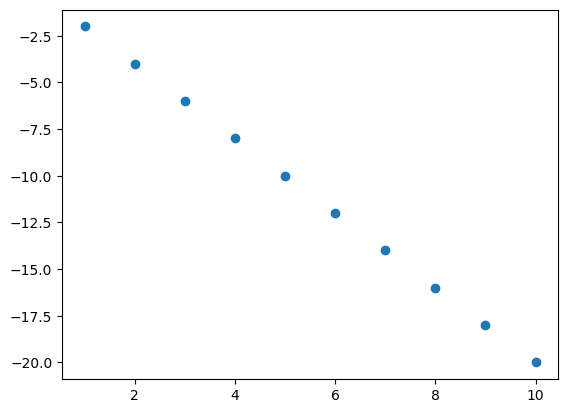

In [50]:
m = 0 
x = np.linspace(1,10,10)
y = equ(-2,x,0)

print(np.corrcoef(x,y))
plt.scatter(x,y)
plt.show()

[[1.         0.77939755]
 [0.77939755 1.        ]]


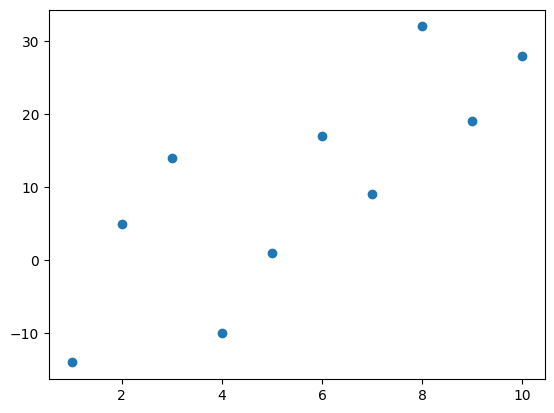

In [65]:
m = 0 
x = np.linspace(1,10,10)
c = np.random.randint(-20,20,10)
y = equ(2,x,c)

print(np.corrcoef(x,y))
plt.scatter(x,y)
plt.show()


## 1. Sample Autocorrelation Formula
For a given time series $y_1, y_2, \dots, y_T$, the sample autocorrelation coefficient at lag $k$ (denoted as $r_k$) is calculated as: 
$r_k = \frac{\sum_{t=k+1}^{T} (y_t - \bar{y})(y_{t-k} - \bar{y})}{\sum_{t=1}^{T} (y_t - \bar{y})^2}$



In [ ]:

y = [1,2,3,4,5,6,7,8,9,10]
print(np.mean(y))

n = len(y)
lag = 3 

print(y[:n-lag])
print(y[lag:])

5.5
[1, 2, 3, 4, 5, 6, 7]
[4, 5, 6, 7, 8, 9, 10]


Maximum correlation: 0.22097762406212498
Minimum correlation: -0.14088838451693397


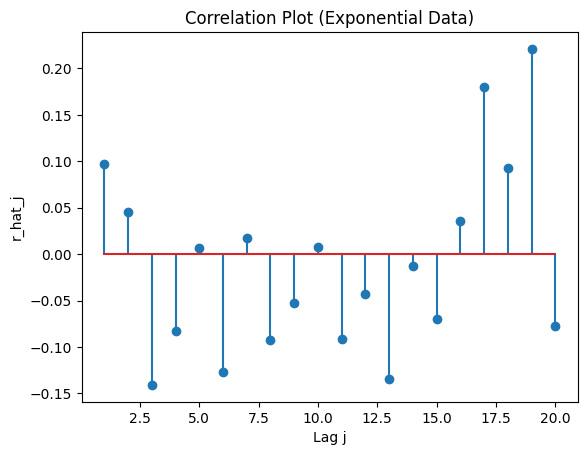

In [32]:

# numpy scale = mean:
np.random.seed(42)
x = np.random.exponential(scale=1,size=100)

def autocorelation(x,lag):
    n = len(x)
    mean = np.mean(x)
    # lagged covariance
    num = np.sum((x[:n-lag] - mean) * (x[lag:]-mean))
    # variance normalization 
    denom = np.sum((x-mean)**2)
    return num/denom 

lags = 20 
r = [autocorelation(x,j) for j in range(1,lags+1)]

max_corr = np.max(r)
min_corr = np.min(r)

print("Maximum correlation:", max_corr)
print("Minimum correlation:", min_corr)

plt.stem(range(1,lags+1),r)
plt.title("Correlation Plot (Exponential Data)")
plt.xlabel("Lag j")
plt.ylabel("r_hat_j")
plt.show()
    

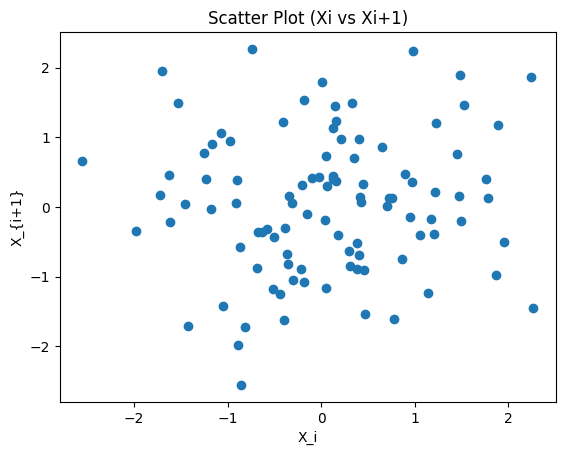

In [ ]:

# proof of independence:
plt.scatter(X[:-1], X[1:])
plt.title("Scatter Plot (Xi vs Xi+1)")
plt.xlabel("X_i")
plt.ylabel("X_{i+1}")
plt.show()

In [38]:

# m/m/1 queue simulations:
import numpy as np 
import matplotlib.pyplot as plt 

np.random.seed(42)

n = 100

""" 
arival_rate = (high) server busy
service_rate = (high) idle time increase 
utilization u_hat(n) = server busy / total time = arival_rate / service_rate  
"""
arrival_rate = 0.8 
service_rate = 1.0

inter_arival_time = np.random.exponential(scale=1/arrival_rate,size=n)
service_time = np.random.exponential(scale=1/service_rate,size=n)

""" 
Arrivals: 0.4,1.6,2.1 then 
inter-arrival-time:
A1 = 0 - 0.4  = 0.2
A2 = 1.6 - 0.4 = 1.2
"""
arrival_time = np.cumsum(inter_arival_time)

start_service = np.zeros(n)
departure_time = np.zeros(n)
waiting_time = np.zeros(n)


for i in range(n):
    if i==0:
        start_service[i] = arrival_time[i]
    else:
        start_service[i] = max(arrival_time[i],departure_time[i-1])
    waiting_time[i] = start_service[i] - arrival_time[i]
    departure_time[i] = start_service[i] + service_time[i]

X = waiting_time

Maximum correlation
0.913
Minimum correlation
0.031


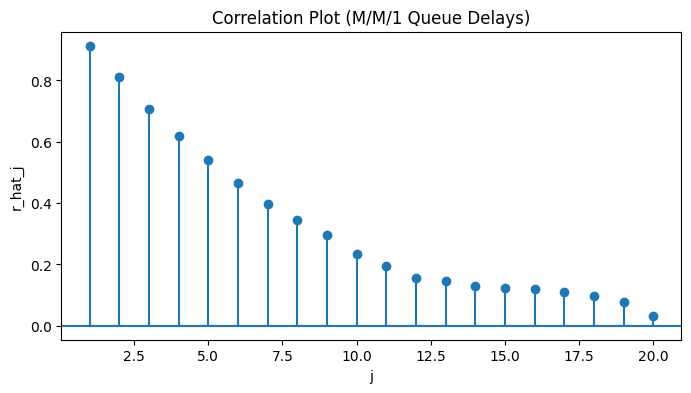

In [40]:

lags = 20
r = [autocorelation(X, j) for j in range(1, lags+1)]
plt.figure(figsize=(8,4))
plt.stem(range(1, lags+1), r)
plt.axhline(0)

print(f"Maximum correlation\n{max(r):.3f}")
print(f"Minimum correlation\n{min(r):.3f}")

plt.xlabel("j")
plt.ylabel("r_hat_j")
plt.title("Correlation Plot (M/M/1 Queue Delays)")

plt.show()

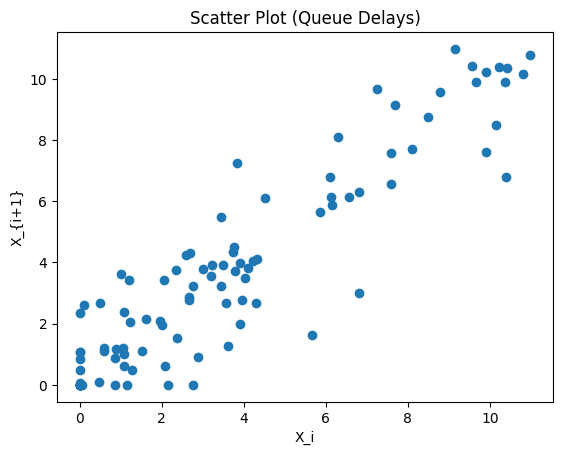

In [41]:
plt.scatter(X[:-1], X[1:])
plt.xlabel("X_i")
plt.ylabel("X_{i+1}")
plt.title("Scatter Plot (Queue Delays)")
plt.show()


# 6.4.2

In [119]:
print(3/15)

0.2


0.15789473684210525


(array([3., 3., 5., 8.]),
 array([1., 2., 3., 4., 5.]),
 <BarContainer object of 4 artists>)

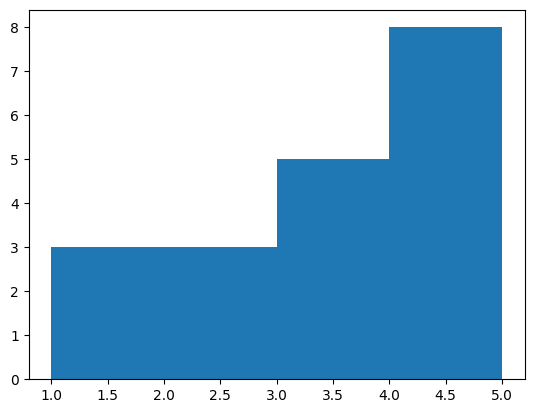

In [ ]:
import numpy as np 
import matplotlib.pyplot as plt 

x = np.array([1,2,3,4,5,1,2,3,4,5,1,2,3,4,5,3,3,4,4])
"""
min = 1 
max = 5
width = (5-1)/(bin=4)=1
(min,bin) like this 
(1,2) (2,3) (3,4), (4,5)
(1,2)-> count(1 ase 3 ta)
(2,3) -> count(2 ase 3 ta)
(3,4) -> count(3 ase 5 ta)

inclusive:
(4-5) -> count(4 ase 5 ta, 5 ase 3 ta total 8)

================================================
(array([3., 3., 5., 8.]),
array([1., 2., 3., 4., 5.]),
if density = True then,
Density = Count/(Total_count*Bin_Width)
"""
print(3/(len(x)*1))

#plt.hist(x,bins=4,density=True)
plt.hist(x,bins=4)


In [ ]:

# ========== theoretically distribution ==========
import numpy as np 
import scipy.stats as stats 
import matplotlib.pyplot as plt 
import plotly.graph_objects as go 

mean = 400
std = 100

# take x-value from random noise(but ordered must):
x = np.linspace(0,800,1000)
y = stats.norm.pdf(x,loc=mean,scale=std)

trace1 = go.Scatter(x=x,y=y,mode="lines")
layout = go.Layout(
    xaxis = dict(title="x-value",showgrid=False),
    yaxis = dict(title="density-probability",showgrid=False),
    template = "plotly_dark"
    
)
trace = [trace1]
fig = go.Figure(data=trace,layout=layout)
fig


In [23]:

x = np.random.normal(loc=mean,scale=std,size=1000)
x = np.sort(x)
y = stats.norm.pdf(x,loc=mean,scale=std)
trace1 = go.Scatter(x=x,y=y,mode="lines")
layout = go.Layout(
    xaxis = dict(title="x-value",showgrid=False),
    yaxis = dict(title="density-probability",showgrid=False),
    template = "plotly_dark"
    
)
trace = [trace1]
fig = go.Figure(data=trace,layout=layout)
fig


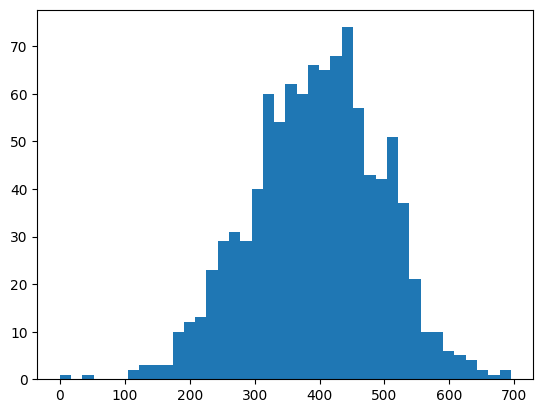

In [43]:

x = np.random.normal(loc=mean,scale=std,size=1000)
plt.hist(x=x,bins=40)
plt.show()

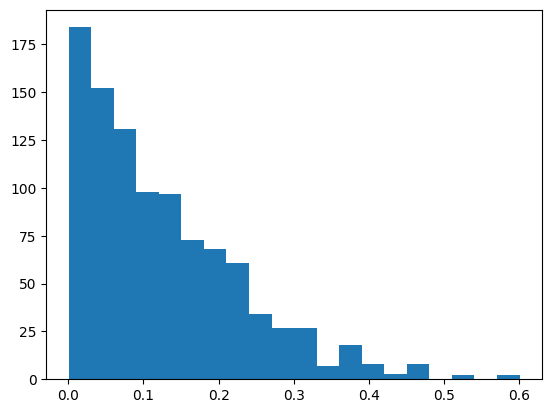

In [147]:

# beta distribution:
x = np.random.beta(a=1.1,b=8,size=1000)
plt.hist(x,bins=20)
plt.show()

<Axes: ylabel='Count'>

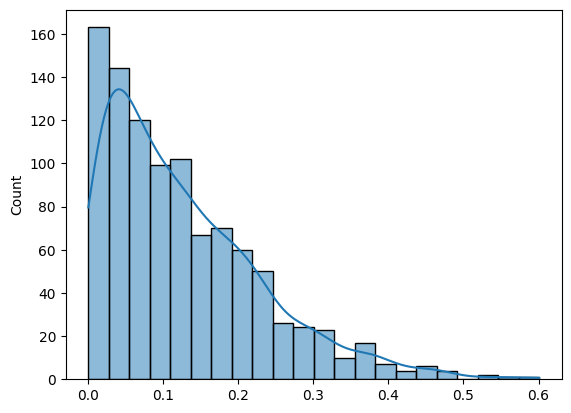

In [148]:
import seaborn as sns 
sns.histplot(x,kde=True)

<Axes: ylabel='Count'>

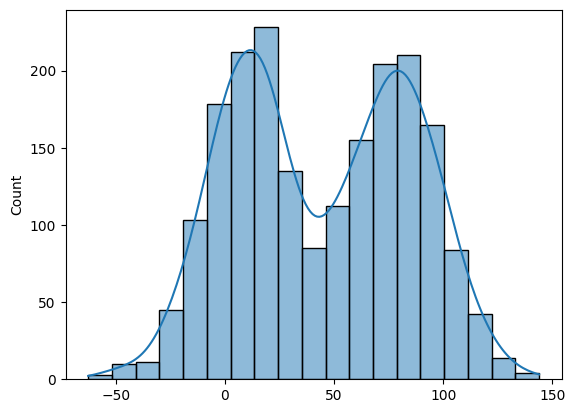

In [63]:

x1 = np.random.normal(loc=10,scale=20,size=1000)
x2 = np.random.normal(loc=80,scale=20,size=1000)
x = np.concatenate([x1,x2])
sns.histplot(x,kde=True)


# 6.4.3: 

**Box plot:** A box plot is a graphical representation of the five number summary statistics. It is also known as a box-and-whisker plot. It is used to see the distribution of the data and to detect outliers graphically/visual.



**Five Number Summary Statistics includes the following values:**

- Minimum Value: The smallest value in the data set.
- First Quartile ($Q_1$): The value that separates the lowest 25% of the data from the remaining data sets.
- Median ($Q_2$): The value that separates the lowest 50% from the highest 50% of the data.
- Third Quartile ($Q_3$): The value that separates the lowest 75% of the data from the highest 25% of the data.
- Maximum value: The largest value in the data set.


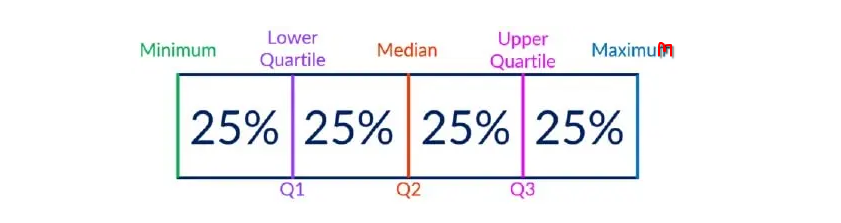

In [142]:
from IPython.display import Image
Image("../../img/img19.png")


### Interquartile Range:
The interquartile range (IQR) is a measure of variability that is based on the five number summary of a dataset. It is the difference between the third quartile ($Q_3$) and the first quartile ($Q_1$) of a data set. <br>
IQR = $Q_3$ - $Q_1$


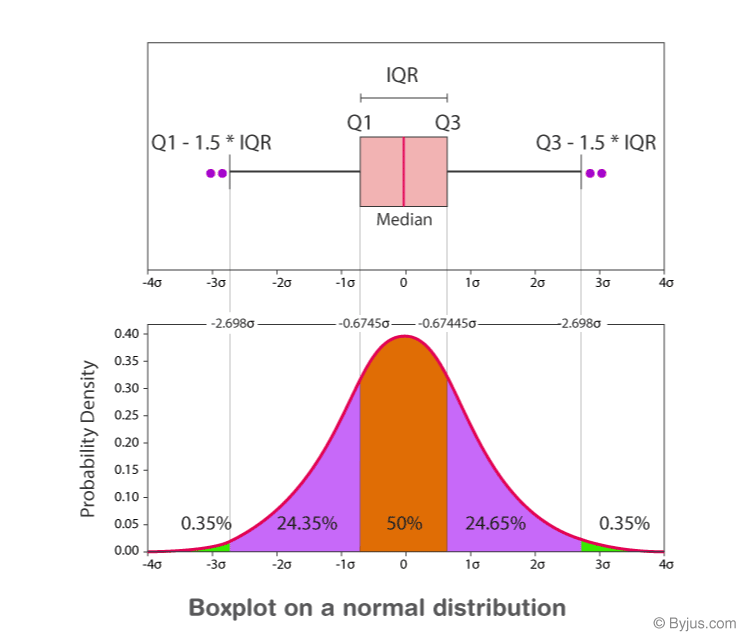

In [141]:
from IPython.display import Image
Image("../../img/img18.png")

In [149]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
from scipy.stats import skew
import matplotlib.pyplot as plt 

a = [ 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.02, 0.02, 0.03, 0.03, 0.03, 0.04, 0.04, 0.04, 
  0.04, 0.04, 0.04, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.06, 0.06, 0.06, 0.06, 
  0.07, 0.07, 0.07, 0.07, 0.07, 0.07, 0.07, 0.07, 0.07, 0.07, 0.08, 0.08, 0.08, 0.08, 0.08, 0.09, 
  0.09, 0.10, 0.10, 0.10, 0.10, 0.10, 0.10, 0.10, 0.10, 0.11, 0.11, 0.11, 0.11, 0.11, 0.11, 0.12, 
  0.12, 0.12, 0.12, 0.13, 0.13, 0.14, 0.14, 0.14, 0.14, 0.14, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 
  0.17, 0.18, 0.19, 0.19, 0.19, 0.20, 0.21, 0.21, 0.21, 0.21, 0.21, 0.21, 0.22, 0.22, 0.22, 0.23, 
  0.23, 0.23, 0.23, 0.23, 0.23, 0.24, 0.25, 0.25, 0.25, 0.25, 0.25, 0.25, 0.26, 0.26, 0.26, 0.26, 
  0.26, 0.27, 0.28, 0.28, 0.29, 0.29, 0.30, 0.31, 0.31, 0.32, 0.35, 0.35, 0.35, 0.36, 0.36, 0.36, 
  0.37, 0.37, 0.38, 0.38, 0.38, 0.38, 0.38, 0.38, 0.39, 0.39, 0.40, 0.40, 0.41, 0.41, 0.43, 0.43, 
  0.43, 0.44, 0.45, 0.45, 0.46, 0.47, 0.47, 0.47, 0.48, 0.49, 0.49, 0.49, 0.49, 0.50, 0.50, 0.50, 
  0.50, 0.51, 0.51, 0.51, 0.52, 0.52, 0.53, 0.53, 0.53, 0.53, 0.54, 0.54, 0.54, 0.55, 0.55, 0.56, 
  0.57, 0.57, 0.60, 0.61, 0.61, 0.63, 0.63, 0.64, 0.65, 0.65, 0.65, 0.69, 0.69, 0.70, 0.72, 0.72, 
  0.72, 0.74, 0.75, 0.76, 0.77, 0.79, 0.84, 0.86, 0.87, 0.88, 0.88, 0.90, 0.93, 0.93, 0.95, 0.97, 
  1.03, 1.05, 1.05, 1.06, 1.09, 1.10, 1.11, 1.12, 1.17, 1.18, 1.24, 1.24, 1.28, 1.33, 1.38, 1.44, 
  1.51, 1.72, 1.83, 1.96]
interarrivals =  np.array(a)
print(f"Minimum: {interarrivals.min()}")
print(f"Maximum: {interarrivals.max()}")
print(f"Mean: {interarrivals.mean():.4f}")
print(f"Median: {np.median(interarrivals):.4f}")
print(f"variance: {interarrivals.var():.4f}")
print(f"co-efficient variance: {interarrivals.std()/interarrivals.mean():.4f}")
print(f"skewness: {skew(interarrivals):.4f}")


Minimum: 0.01
Maximum: 1.96
Mean: 0.3971
Median: 0.2750
variance: 0.1388
co-efficient variance: 0.9382
skewness: 1.4981


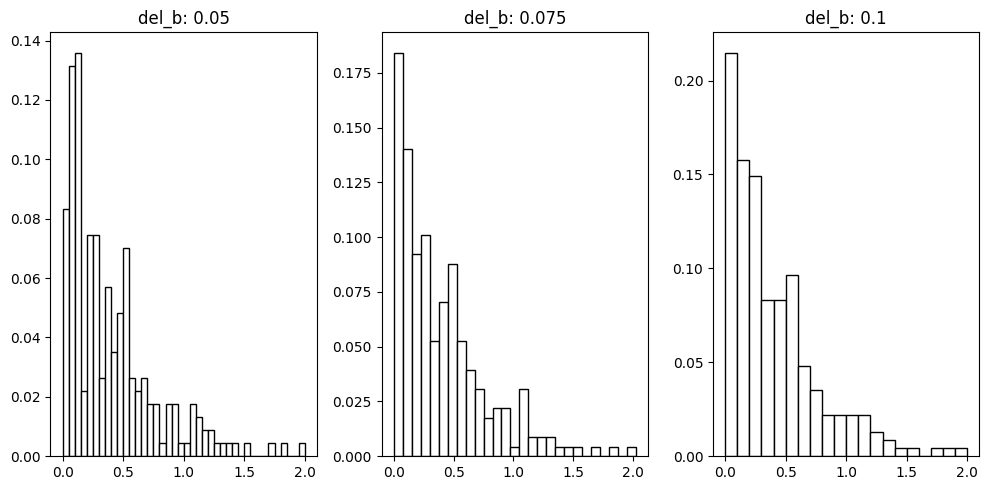

In [135]:

del_b = [0.050,0.075,0.100]
plt.figure(figsize=(10,5))
for idx,val in enumerate(del_b):
    plt.subplot(1,3,idx+1)
    bins = np.arange(0,interarrivals.max()+val,val)
    weights = np.ones_like(interarrivals)/len(interarrivals)
    plt.hist(interarrivals,bins=bins,weights=weights,color="white",edgecolor="black")
    plt.title(f"del_b: {val}")
plt.tight_layout()
plt.show()


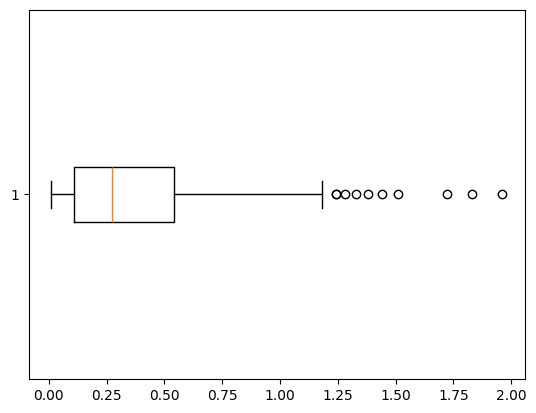

In [ ]:

plt.title("Box-Plot of ")
plt.boxplot(interarrivals,orientation='horizontal')
plt.show()

<br>

# 6.6 Probability Plots and QQ plot:

<br>

In [167]:
from scipy.stats import norm
norm.ppf(0.95)

np.float64(1.6448536269514722)

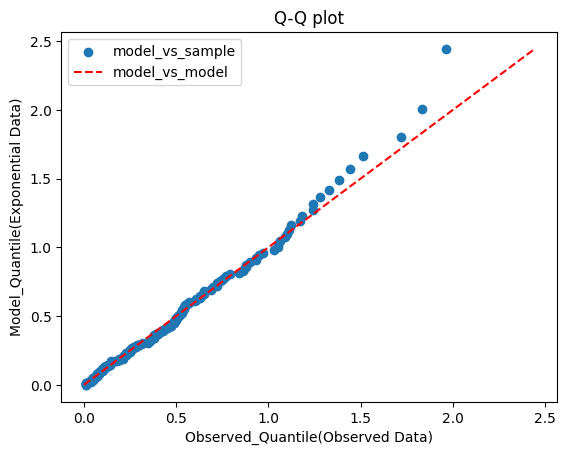

In [168]:
from scipy.stats import expon

data = sorted(interarrivals)
n = len(data)
q  = [(i-0.5)/n for i in range(1,n+1)]

# determine the model quantile value:
# Percent point funtion(ppf) -> inverse of CDF 
# aslo know as ICDF(Inverse Cumulative Distribution Function)
# example_6.6 page no: 331 for the data we find the MLE or beta_hat
beta_hat = 0.399
model_quantile = expon.ppf(q,scale=beta_hat)

# sample quantile 
sample_quantile = data 

plt.scatter(sample_quantile,model_quantile,label="model_vs_sample")
plt.plot(model_quantile, model_quantile, 'r--',label="model_vs_model") 
plt.xlabel("Observed_Quantile(Observed Data)")
plt.ylabel("Model_Quantile(Exponential Data)")
plt.title("Q-Q plot")
plt.legend()
plt.show()



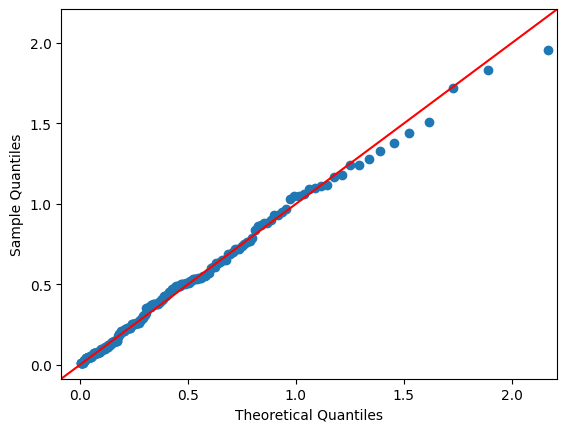

In [ ]:

# draw qq plot with statsmodels:
import statsmodels.api as sm 
data = interarrivals

# axis (ulta hoise)
sm.qqplot(data,dist=expon,scale=beta_hat,line="45")
plt.show()


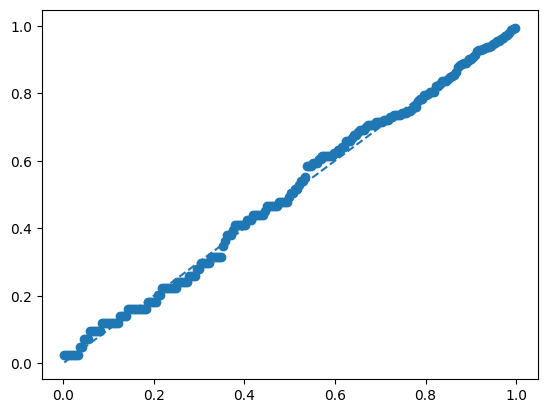

In [183]:

# p-p plot:
data = sorted(interarrivals)
n = len(data)
q = [(i-0.5)/n for i in range(1,n+1)]

models_prob = expon.cdf(data,scale=beta_hat)

plt.scatter(q,models_prob)
plt.plot(q,q,'--')
plt.show()
